CSV shape: (6, 3)
CSV data types:
 Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object
Run1_mol_L: mean = 0.537, standard deviation = 0.293
Run2_mol_L: mean = 0.403, standard deviation = 0.349
Run2 shows more variation.


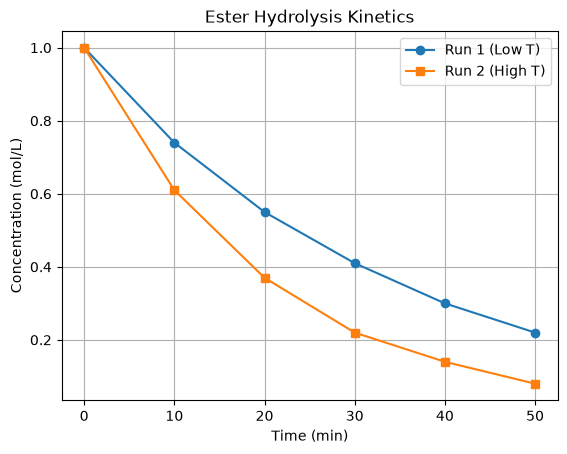

Mean k (P·V): 4.024 bar·L


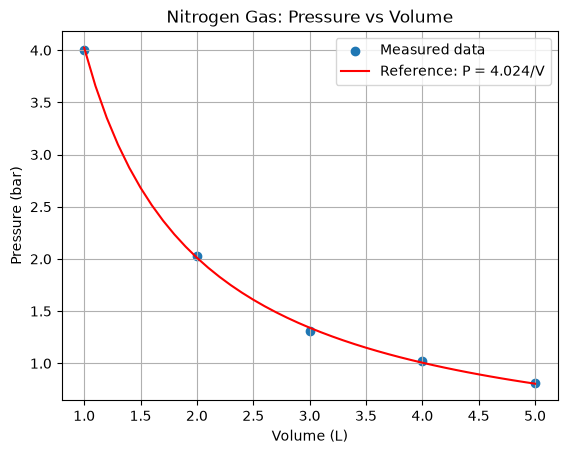

In [1]:
import pandas as pd

import matplotlib.pyplot as plt

# Kinetics data
kinetics_df = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [1.00, 0.74, 0.55, 0.41, 0.30, 0.22],
    "Run2_mol_L": [1.00, 0.61, 0.37, 0.22, 0.14, 0.08],
})

kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=2)

kinetics_readback = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_readback.shape)
print("CSV data types:\n", kinetics_readback.dtypes)

for run in ["Run1_mol_L", "Run2_mol_L"]:
    print(f"{run}: mean = {kinetics_df[run].mean():.3f}, "
          f"standard deviation = {kinetics_df[run].std():.3f}")

if kinetics_df["Run1_mol_L"].std() > kinetics_df["Run2_mol_L"].std():
    print("Run1 shows more variation.")
else:
    print("Run2 shows more variation.")

plt.figure()
plt.plot(kinetics_df["Time_min"], kinetics_df["Run1_mol_L"], marker="o", label="Run 1 (Low T)")
plt.plot(kinetics_df["Time_min"], kinetics_df["Run2_mol_L"], marker="s", label="Run 2 (High T)")
plt.title("Ester Hydrolysis Kinetics")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.show()

# Nitrogen gas pressure-volume data
volume_L = [1, 2, 3, 4, 5]
pressure_bar = [4.00, 2.03, 1.31, 1.02, 0.81]

pv_values = [p * v for p, v in zip(pressure_bar, volume_L)]
k = sum(pv_values) / len(pv_values)
print(f"Mean k (P·V): {k:.3f} bar·L")

reference_volume = [v / 10 for v in range(10, 51)]
reference_pressure = [k / v for v in reference_volume]

plt.figure()
plt.scatter(volume_L, pressure_bar, label="Measured data")
plt.plot(reference_volume, reference_pressure, color="red", label=f"Reference: P = {k:.3f}/V")
plt.title("Nitrogen Gas: Pressure vs Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.show()